# Solar Energy Prediction Using Weather Data
**Reproducible academic notebook** | Linear Regression and Random Forest

Run cells from top to bottom in Google Colab. Upload the original Excel file when prompted. The dataset spans 2017–2022; the optional January 2026 calculation is a **historical-weather scenario**, not a validated 2026 forecast.

## 1. Imports and dataset upload

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")
print("Upload the original solar weather Excel file (.xlsx)")
uploaded = files.upload()
excel_files = [name for name in uploaded if name.lower().endswith(".xlsx")]
if not excel_files:
    raise ValueError("Please upload the original .xlsx dataset.")
filename = excel_files[0]
df_raw = pd.read_excel(filename)
print("Original shape:", df_raw.shape)
display(df_raw.head())

Upload the original solar weather Excel file (.xlsx)


Saving solar_weather - Raw - Assignment Oct 2025-1.xlsx to solar_weather - Raw - Assignment Oct 2025-1.xlsx
Original shape: (196777, 7)


,Time,Energy Captured[Wh],Sun Light Intensity (W/m2),Temperature,1 Hour Rain Fall,Cloud Coverage,Length of Day_Light
0,2017-01-01 00:00:00,0,0,1.6,0,100,450
1,2017-01-01 00:15:00,0,0,1.6,0,100,450
2,2017-01-01 00:30:00,0,0,1.6,0,100,450
3,2017-01-01 00:45:00,0,0,1.6,0,100,450
4,2017-01-01 01:00:00,0,0,1.7,0,100,450


## 2. Validate columns and inspect the raw dataset

In [2]:
target = "Energy Captured[Wh]"
weather_cols = ["Sun Light Intensity (W/m2)", "Temperature", "1 Hour Rain Fall", "Cloud Coverage", "Length of Day_Light"]
required = ["Time", target] + weather_cols
missing_columns = [c for c in required if c not in df_raw.columns]
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}. Available: {df_raw.columns.tolist()}")
df = df_raw[required].copy()
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")
for col in [target] + weather_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
print("Missing values BEFORE cleaning:")
print(df.isna().sum())
print("Duplicate timestamps excluding NaT:", df.loc[df["Time"].notna(), "Time"].duplicated().sum())
print("Date range:", df["Time"].min(), "to", df["Time"].max())
display(df.describe(include="all").T)

Missing values BEFORE cleaning:
Time                           8
Energy Captured[Wh]            4
Sun Light Intensity (W/m2)     7
Temperature                    6
1 Hour Rain Fall               4
Cloud Coverage                13
Length of Day_Light            5
dtype: int64
Duplicate timestamps excluding NaT: 1
Date range: 2017-01-01 00:00:00 to 2022-08-31 17:45:00


,count,mean,min,25%,50%,75%,max,std
Time,196769,2019-10-29 23:36:25.935792128,2017-01-01 00:00:00,2018-06-02 11:45:00,2019-10-28 21:45:00,2021-03-24 07:45:00,2022-08-31 17:45:00,NaN
Energy Captured[Wh],196773.0,573.011262,-54.0,0.0,0.0,577.0,5020.0,1044.832388
Sun Light Intensity (W/m2),196770.0,32.598451,0.0,0.0,1.6,46.8,270.0,52.175402
Temperature,196771.0,9.790703,-16.6,3.6,9.3,15.7,35.8,7.995447
1 Hour Rain Fall,196773.0,0.066036,0.0,0.0,0.0,0.0,8.09,0.278915
Cloud Coverage,196764.0,65.970798,-250.0,34.0,82.0,100.0,101.0,36.637595
Length of Day_Light,196772.0,748.650189,450.0,570.0,765.0,930.0,1020.0,194.867878


## 3. Clean timestamps and duplicates
Rows with invalid timestamps are excluded because their true chronological positions cannot be established. Exact duplicate records are removed. We do **not** fill missing target values with future or invented energy values.

In [3]:
before = len(df)
df = df.dropna(subset=["Time", target] + weather_cols).copy()
df = df.drop_duplicates().sort_values("Time").reset_index(drop=True)
# Do not silently remove non-identical rows sharing the same timestamp.
conflicting_times = df["Time"].duplicated(keep=False)
if conflicting_times.any():
    display(df.loc[conflicting_times])
    raise ValueError("Conflicting measurements at the same timestamp; inspect before proceeding.")
print("Rows removed:", before - len(df))
print("Clean shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate timestamps:", df["Time"].duplicated().sum())
print("Chronologically sorted:", df["Time"].is_monotonic_increasing)
print("Most common time gaps:")
print(df["Time"].diff().value_counts().head(10))

Rows removed: 48
Clean shape: (196729, 7)
Missing values: 0
Duplicate timestamps: 0
Chronologically sorted: True
Most common time gaps:
Time
0 days 00:15:00    196672
0 days 00:30:00        45
1 days 00:15:00         6
2 days 00:15:00         2
5 days 00:15:00         1
0 days 00:45:00         1
4 days 00:15:00         1
Name: count, dtype: int64


## 4. Exploratory data analysis

,count,mean,std,min,25%,50%,75%,max
Energy Captured[Wh],196729.0,573.081112,1044.873647,-54.0,0.0,0.0,578.0,5020.00
Sun Light Intensity (W/m2),196729.0,32.603140,52.178338,0.0,0.0,1.6,46.8,270.00
Temperature,196729.0,9.792591,7.994938,-16.6,3.6,9.3,15.7,35.80
1 Hour Rain Fall,196729.0,0.066038,0.278918,0.0,0.0,0.0,0.0,8.09
Cloud Coverage,196729.0,65.968520,36.638604,-250.0,34.0,82.0,100.0,101.00
Length of Day_Light,196729.0,748.707308,194.846961,450.0,570.0,765.0,930.0,1020.00


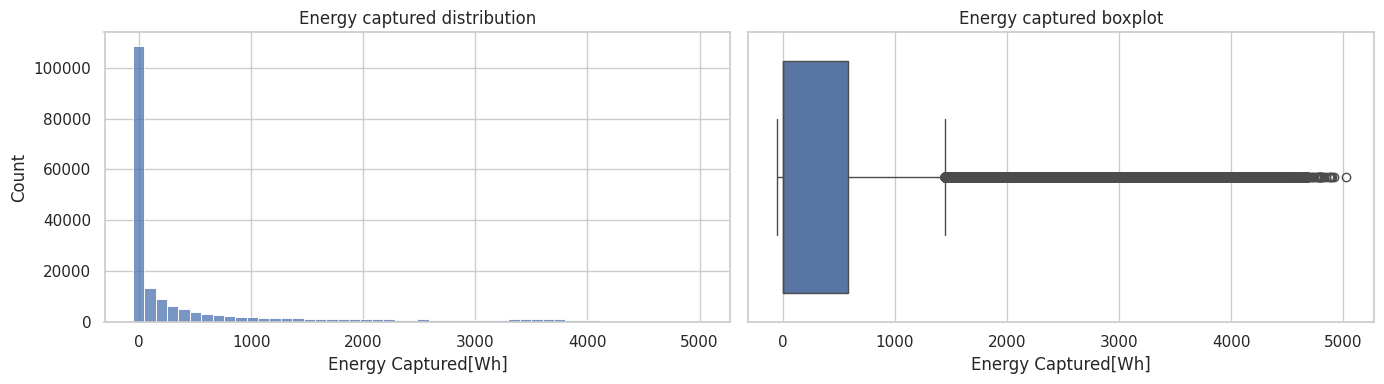

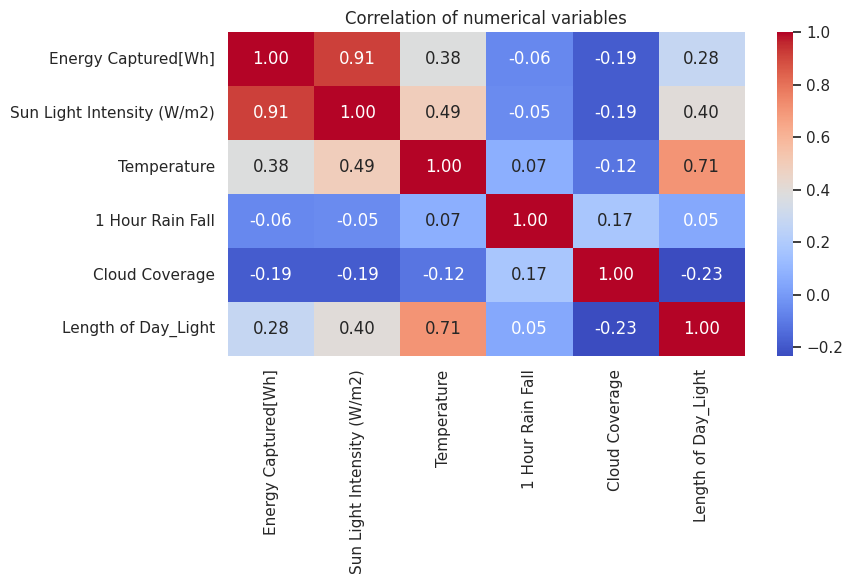

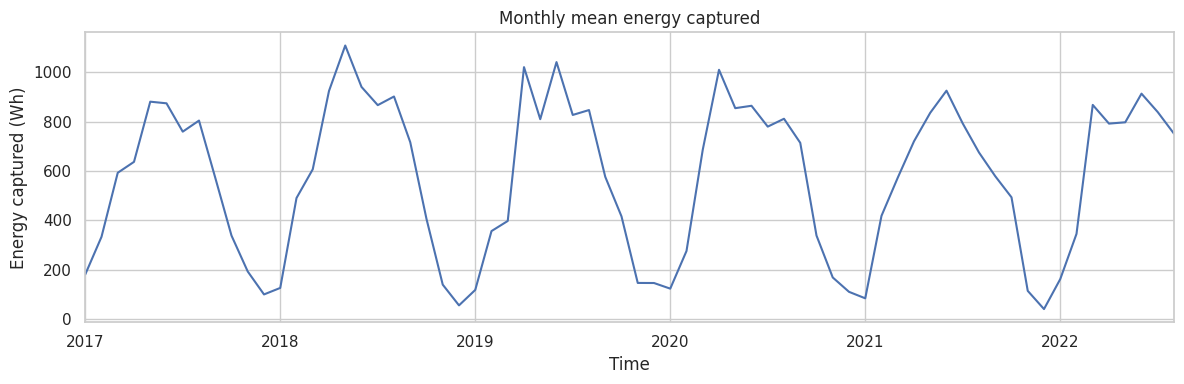

In [4]:
display(df[[target] + weather_cols].describe().T)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df[target], bins=50, ax=axes[0]); axes[0].set_title("Energy captured distribution")
sns.boxplot(x=df[target], ax=axes[1]); axes[1].set_title("Energy captured boxplot")
plt.tight_layout(); plt.show()
plt.figure(figsize=(9, 6))
sns.heatmap(df[[target] + weather_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation of numerical variables"); plt.tight_layout(); plt.show()
monthly = df.set_index("Time")[target].resample("MS").mean()
plt.figure(figsize=(12, 4)); monthly.plot(); plt.title("Monthly mean energy captured"); plt.ylabel("Energy captured (Wh)"); plt.tight_layout(); plt.show()

## 5. Feature engineering
Calendar variables are known in advance. The weather variables here are **observed** conditions, so the resulting model estimates energy from contemporaneous weather; it is not an operational ahead-of-time forecast unless appropriate weather forecasts are supplied. No lag features are assumed.

In [5]:
df["Hour"] = df["Time"].dt.hour
# Include minute to represent the 15-minute sampling grid
df["Minute"] = df["Time"].dt.minute
df["Month"] = df["Time"].dt.month
df["Year"] = df["Time"].dt.year
df["DayOfYear"] = df["Time"].dt.dayofyear
# Cyclical calendar features
time_of_day = df["Hour"] + df["Minute"] / 60
df["Hour_sin"] = np.sin(2*np.pi*time_of_day/24)
df["Hour_cos"] = np.cos(2*np.pi*time_of_day/24)
df["Day_sin"] = np.sin(2*np.pi*df["DayOfYear"]/365.25)
df["Day_cos"] = np.cos(2*np.pi*df["DayOfYear"]/365.25)
feature_cols = weather_cols + ["Year", "Hour_sin", "Hour_cos", "Day_sin", "Day_cos"]
print("Model features:", feature_cols)
display(df[["Time", target] + feature_cols].head())

Model features: ['Sun Light Intensity (W/m2)', 'Temperature', '1 Hour Rain Fall', 'Cloud Coverage', 'Length of Day_Light', 'Year', 'Hour_sin', 'Hour_cos', 'Day_sin', 'Day_cos']


,Time,Energy Captured[Wh],Sun Light Intensity (W/m2),Temperature,1 Hour Rain Fall,Cloud Coverage,Length of Day_Light,Year,Hour_sin,Hour_cos,Day_sin,Day_cos
0,2017-01-01 00:00:00,0.0,0.0,1.6,0.0,100.0,450.0,2017,0.000000,1.000000,0.017202,0.999852
1,2017-01-01 00:15:00,0.0,0.0,1.6,0.0,100.0,450.0,2017,0.065403,0.997859,0.017202,0.999852
2,2017-01-01 00:30:00,0.0,0.0,1.6,0.0,100.0,450.0,2017,0.130526,0.991445,0.017202,0.999852
3,2017-01-01 00:45:00,0.0,0.0,1.6,0.0,100.0,450.0,2017,0.195090,0.980785,0.017202,0.999852
4,2017-01-01 01:00:00,0.0,0.0,1.7,0.0,100.0,450.0,2017,0.258819,0.965926,0.017202,0.999852


## 6. Chronological 80/20 train–test split
The final 20% of observations is held out as a later time period. No random shuffle. The test set is not used for model selection or tuning.

In [6]:
split_idx = int(len(df)*0.8)
train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()
X_train, y_train = train_df[feature_cols], train_df[target]
X_test, y_test = test_df[feature_cols], test_df[target]
print("Train:", len(train_df), train_df["Time"].min(), "to", train_df["Time"].max())
print("Test:", len(test_df), test_df["Time"].min(), "to", test_df["Time"].max())
assert train_df["Time"].max() < test_df["Time"].min()

Train: 157383 2017-01-01 00:00:00 to 2021-07-04 21:15:00
Test: 39346 2021-07-04 21:30:00 to 2022-08-31 17:45:00


## 7. Train Linear Regression and Random Forest
The Random Forest is configured with moderate complexity for Google Colab. Runtime will depend on available resources.

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=2, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
print("Models trained successfully.")

Models trained successfully.


## 8. Evaluate both models and compare with a baseline
A simple training-mean baseline gives context for model performance. We report test-set metrics only.

In [8]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def metrics(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "MAE (Wh)": mean_absolute_error(y_true, y_pred),
            "MSE (Wh²)": mean_squared_error(y_true, y_pred),
            "RMSE (Wh)": np.sqrt(mean_squared_error(y_true, y_pred))}

baseline = np.full(len(y_test), y_train.mean())
results = pd.DataFrame({
    "Training-mean baseline": metrics(y_test, baseline),
    "Linear Regression": metrics(y_test, pred_lr),
    "Random Forest": metrics(y_test, pred_rf)
}).T
print("Chronological holdout results:")
display(results.round(4))
print("Best ML model by test RMSE:", results.loc[["Linear Regression", "Random Forest"], "RMSE (Wh)"].idxmin())

Chronological holdout results:


,R2,MAE (Wh),MSE (Wh²),RMSE (Wh)
Training-mean baseline,-0.0008,765.1099,1.096383e+06,1047.0831
Linear Regression,0.8249,262.1231,1.918501e+05,438.0070
Random Forest,0.9011,131.6503,1.083759e+05,329.2050


Best ML model by test RMSE: Random Forest


## 9. Plot predictions and feature importance

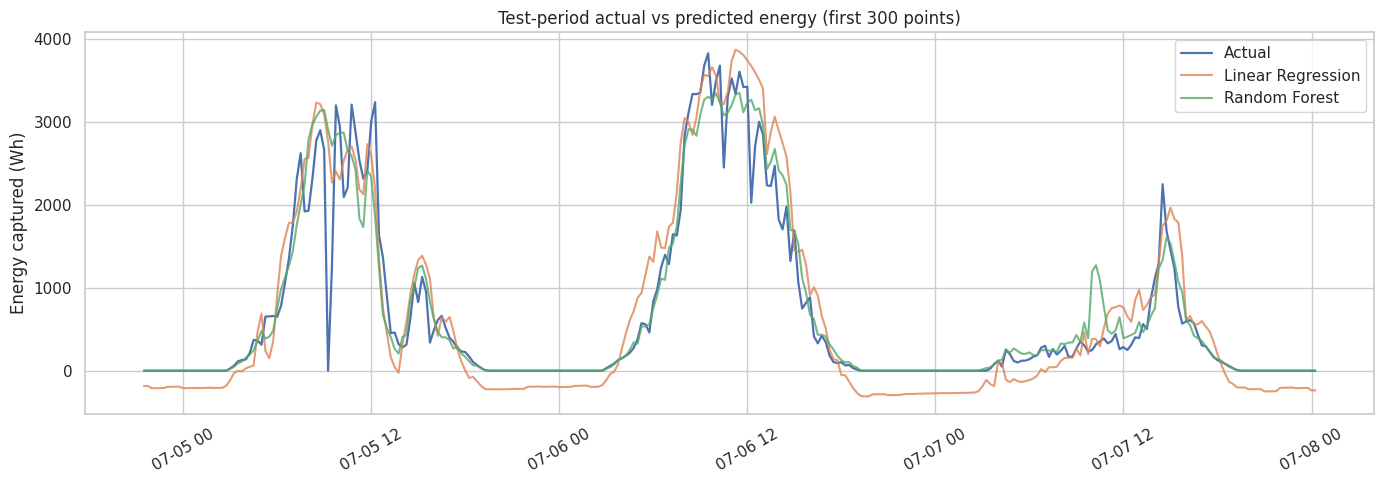

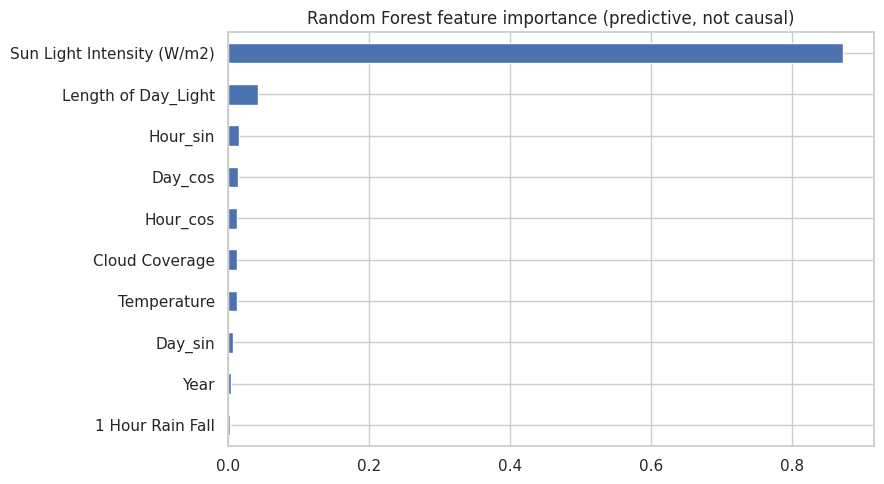

In [9]:
n_show = min(300, len(y_test))
plt.figure(figsize=(14, 5))
plt.plot(test_df["Time"].iloc[:n_show], y_test.iloc[:n_show].values, label="Actual", linewidth=1.6)
plt.plot(test_df["Time"].iloc[:n_show], pred_lr[:n_show], label="Linear Regression", alpha=.8)
plt.plot(test_df["Time"].iloc[:n_show], pred_rf[:n_show], label="Random Forest", alpha=.8)
plt.title("Test-period actual vs predicted energy (first 300 points)")
plt.ylabel("Energy captured (Wh)"); plt.legend(); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values()
plt.figure(figsize=(9, 5)); importance.plot(kind="barh")
plt.title("Random Forest feature importance (predictive, not causal)"); plt.tight_layout(); plt.show()

## 10.January 2026 historical-weather scenario
**Not a real forecast.** This example takes the mean observed January weather and clock-time features from **training data only**, sets the year to 2026, and asks the model for a scenario estimate. It does not account for actual January 2026 weather, changes in the installation, or extrapolation uncertainty. Tree models do not reliably extrapolate to unseen years.

In [10]:
jan_train = train_df[train_df["Time"].dt.month == 1]
if jan_train.empty:
    print("No January observations in training data; scenario skipped.")
else:
    scenario = jan_train[feature_cols].mean().to_frame().T
    scenario["Year"] = 2026
    scenario = scenario[feature_cols]
    scenario_lr = float(lr.predict(scenario)[0])
    scenario_rf = float(rf.predict(scenario)[0])
    print("Hypothetical January 2026 scenario (Wh per observation):")
    print("Linear Regression:", round(scenario_lr, 2))
    print("Random Forest:", round(scenario_rf, 2))
    print("These are not validated 2026 forecasts or monthly energy totals.")

Hypothetical January 2026 scenario (Wh per observation):
Linear Regression: 120.02
Random Forest: 52.78
These are not validated 2026 forecasts or monthly energy totals.


## 11. Save outputs and document limitations

In [11]:
results.to_csv("solar_model_comparison.csv", index_label="Model")
print("Saved solar_model_comparison.csv")
print("Limitations:")
print("1. Contemporaneous observed weather is used, not weather forecasts.")
print("2. Missing timestamps and gaps remain documented; no invented measurements.")
print("3. January 2026 is only a historical-weather scenario.")
print("4. Results depend on this dataset and the chronological holdout period.")

Saved solar_model_comparison.csv
Limitations:
1. Contemporaneous observed weather is used, not weather forecasts.
2. Missing timestamps and gaps remain documented; no invented measurements.
3. January 2026 is only a historical-weather scenario.
4. Results depend on this dataset and the chronological holdout period.
